In [1]:
# One dict per run, every parameter written out. Change one parameter at a time.
EXPERIMENTS = [
    {"group": "baseline",
     "prompt": "wooden cabin, red canoe on the left shore, two pine trees, mountains reflected in the lake, golden sunset light, no people, no text",
     "negative_prompt": "",
     "seed": 42, "steps": 30, "cfg": 7.5, "resolution": "512x512", "scheduler": "PNDM"},

    # Example: copy the baseline, remove the #, change one value (here: steps).
    # {"group": "steps",
    #  "prompt": "wooden cabin, red canoe on the left shore, two pine trees, mountains reflected in the lake, golden sunset light, no people, no text",
    #  "negative_prompt": "",
    #  "seed": 42, "steps": 50, "cfg": 7.5, "resolution": "512x512", "scheduler": "PNDM"},
]

In [2]:
import torch
from pathlib import Path
from IPython.display import display
from PIL import Image
from diffusers import (StableDiffusionPipeline, PNDMScheduler, DDIMScheduler, EulerDiscreteScheduler,
                       EulerAncestralDiscreteScheduler, DPMSolverMultistepScheduler)
from helpers import output_path, append_row

MODEL = "stable-diffusion-v1-5/stable-diffusion-v1-5"
OUT_DIR = "outputs/images"
CSV_PATH = "results/images.csv"

# Names usable in the "scheduler" key
SCHEDULERS = {
    "PNDM": PNDMScheduler,
    "DDIM": DDIMScheduler,
    "Euler": EulerDiscreteScheduler,
    "Euler a": EulerAncestralDiscreteScheduler,
    "DPM++ 2M": DPMSolverMultistepScheduler,
}

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL, dtype=torch.float16, variant="fp16",
    safety_checker=None, requires_safety_checker=False, cache_dir="models",
).to("cuda")
scheduler_config = pipe.scheduler.config  # every run builds its scheduler from this
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)

C:\dev\promt_eng_course\LAB1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1112 23:00:01.931000 27200 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:  41%|████      | 80/196 [00:00<00:00, 778.45it/s]

Loading weights: 100%|██████████| 196/196 [00:00<00:00, 1695.81it/s]


Loading pipeline components...:  50%|█████     | 3/6 [00:00<00:00,  9.26it/s]

Loading pipeline components...: 100%|██████████| 6/6 [00:00<00:00, 15.46it/s]

SKIPPED baseline_fa08e11e.png


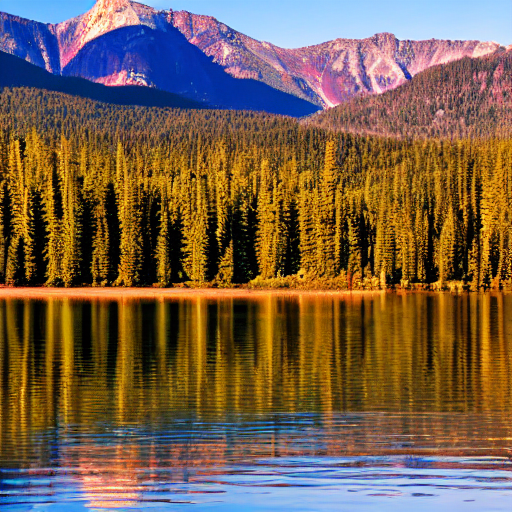

0 new, 1 skipped


In [3]:
new = skipped = 0
for e in EXPERIMENTS:
    path = output_path(e, OUT_DIR, "png")
    if path.exists():
        skipped += 1
        print("SKIPPED", path.name)
    else:
        pipe.scheduler = SCHEDULERS[e["scheduler"]].from_config(scheduler_config)
        width, height = map(int, e["resolution"].split("x"))
        generator = torch.Generator().manual_seed(e["seed"])  # each run seeds itself
        image = pipe(e["prompt"], negative_prompt=e["negative_prompt"], num_inference_steps=e["steps"],
                     guidance_scale=e["cfg"], width=width, height=height, generator=generator).images[0]
        image.save(path)
        append_row(CSV_PATH, e, path.name)
        new += 1
        print("NEW", path.name)
    display(Image.open(path))
print(f"{new} new, {skipped} skipped")